In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
df = pd.read_csv("Datasets/sales_data_sample.csv", encoding='latin1')

In [4]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [5]:
df.shape

(2823, 25)

In [6]:
data = df[['SALES', 'QUANTITYORDERED']].copy()

In [7]:
data = data.dropna()

In [8]:
data.head()

,SALES,QUANTITYORDERED
0,2871.00,30
1,2765.90,34
2,3884.34,41
3,3746.70,45
4,5205.27,49


In [9]:
scaler = StandardScaler()
X = scaler.fit_transform(data)

In [10]:
X[:5]

array([[-0.37082523, -0.52289086],
       [-0.42789707, -0.11220131],
       [ 0.17944282,  0.60650538],
       [ 0.10470098,  1.01719493],
       [ 0.89673966,  1.42788447]])

C:\Users\siddh\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\siddh\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\siddh\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\siddh\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039, in __init__
    self

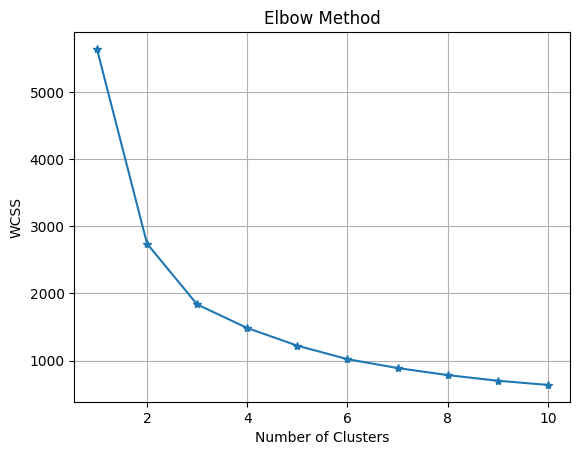

In [11]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='*')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

In [12]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

data['KMeans_Cluster'] = kmeans.fit_predict(X)

print(data.head())

     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               1
1  2765.90               34               2
2  3884.34               41               2
3  3746.70               45               2
4  5205.27               49               0


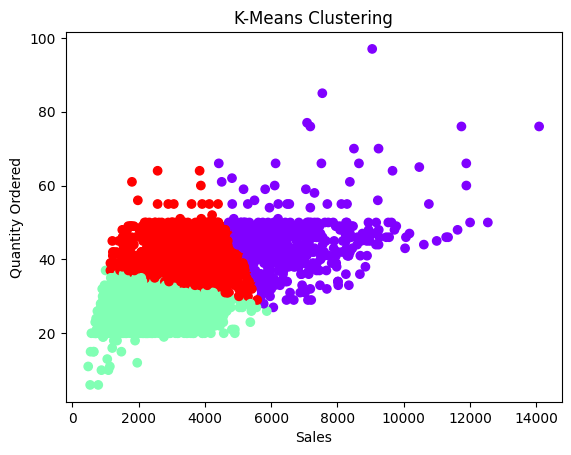

In [13]:
plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=data['KMeans_Cluster'], cmap='rainbow')

plt.title("K-Means Clustering")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()

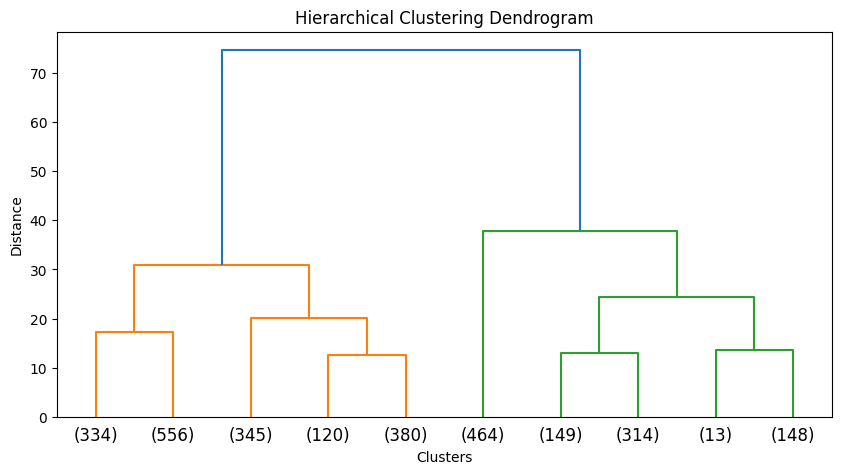

In [14]:
linked = linkage(X, method='ward')

plt.figure(figsize=(10, 5))

dendrogram(linked, truncate_mode='lastp', p=10)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

In [15]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')

data['Hierarchical_Cluster'] = hc.fit_predict(X)

print(data.head())

     SALES  QUANTITYORDERED  KMeans_Cluster  Hierarchical_Cluster
0  2871.00               30               1                     0
1  2765.90               34               2                     0
2  3884.34               41               2                     0
3  3746.70               45               2                     2
4  5205.27               49               0                     1


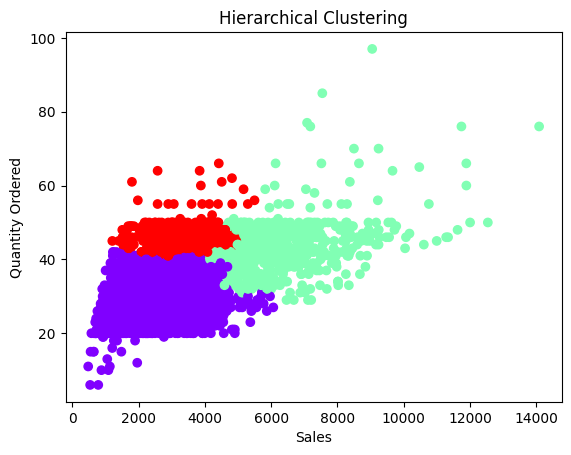

In [16]:
plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=data['Hierarchical_Cluster'], cmap='rainbow')

plt.title("Hierarchical Clustering")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()